In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import smlp

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

indicator_encoder = clslib.TokenIndicator(bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
hidden_dim=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['singleMLP_indic-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/singleMLP_indic-enc/seed-{seed}"

    my_classifiers['singleMLP_indic-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=indicator_encoder,
            model_option='smlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': hidden_dim,
                'dropout': dropout,
                'batch_size': batch_size,
                'learning_rate': learning_rate,
                'weight_decay': weight_decay,
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 20.515 seconds
Dataloader done! Time taken: 0.647 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\smlp.py:68: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.5106 | train acc: 0.7458 | val loss: 0.4207 | val acc: 0.8091
Epoch 02 | train loss: 0.3768 | train acc: 0.8332 | val loss: 0.3551 | val acc: 0.8473
Epoch 03 | train loss: 0.2988 | train acc: 0.8771 | val loss: 0.3050 | val acc: 0.8745
Epoch 04 | train loss: 0.2354 | train acc: 0.9074 | val loss: 0.2702 | val acc: 0.8941
Epoch 05 | train loss: 0.1918 | train acc: 0.9277 | val loss: 0.2542 | val acc: 0.9022
Epoch 06 | train loss: 0.1598 | train acc: 0.9411 | val loss: 0.2432 | val acc: 0.9082
Epoch 07 | train loss: 0.1352 | train acc: 0.9522 | val loss: 0.2366 | val acc: 0.9116
Epoch 08 | train loss: 0.1163 | train acc: 0.9591 | val loss: 0.2361 | val acc: 0.9128
Epoch 09 | train loss: 0.1034 | train acc: 0.9639 | val loss: 0.2388 | val acc: 0.9169
Epoch 10 | train loss: 0.0914 | train acc: 0.9696 | val loss: 0.2429 | val acc: 0.9151
Training done! Time taken: 95.940 seconds
Transforming documents...
Document transformation done! Time taken: 20.748 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5086 | train acc: 0.7459 | val loss: 0.4274 | val acc: 0.8065
Epoch 02 | train loss: 0.3746 | train acc: 0.8352 | val loss: 0.3629 | val acc: 0.8427
Epoch 03 | train loss: 0.2946 | train acc: 0.8789 | val loss: 0.3154 | val acc: 0.8720
Epoch 04 | train loss: 0.2336 | train acc: 0.9090 | val loss: 0.2837 | val acc: 0.8863
Epoch 05 | train loss: 0.1895 | train acc: 0.9287 | val loss: 0.2641 | val acc: 0.8941
Epoch 06 | train loss: 0.1576 | train acc: 0.9423 | val loss: 0.2564 | val acc: 0.9022
Epoch 07 | train loss: 0.1332 | train acc: 0.9529 | val loss: 0.2542 | val acc: 0.9047
Epoch 08 | train loss: 0.1160 | train acc: 0.9594 | val loss: 0.2513 | val acc: 0.9072
Epoch 09 | train loss: 0.1000 | train acc: 0.9663 | val loss: 0.2525 | val acc: 0.9108
Epoch 10 | train loss: 0.0903 | train acc: 0.9692 | val loss: 0.2566 | val acc: 0.9106
Training done! Time taken: 100.169 seconds
Transforming documents...
Document transformation done! Time taken: 22.174 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5072 | train acc: 0.7482 | val loss: 0.4286 | val acc: 0.8012
Epoch 02 | train loss: 0.3780 | train acc: 0.8331 | val loss: 0.3663 | val acc: 0.8393
Epoch 03 | train loss: 0.3001 | train acc: 0.8751 | val loss: 0.3154 | val acc: 0.8698
Epoch 04 | train loss: 0.2382 | train acc: 0.9074 | val loss: 0.2860 | val acc: 0.8856
Epoch 05 | train loss: 0.1927 | train acc: 0.9286 | val loss: 0.2650 | val acc: 0.8939
Epoch 06 | train loss: 0.1605 | train acc: 0.9420 | val loss: 0.2553 | val acc: 0.9010
Epoch 07 | train loss: 0.1344 | train acc: 0.9524 | val loss: 0.2524 | val acc: 0.9045
Epoch 08 | train loss: 0.1156 | train acc: 0.9600 | val loss: 0.2499 | val acc: 0.9057
Epoch 09 | train loss: 0.1012 | train acc: 0.9654 | val loss: 0.2535 | val acc: 0.9095
Epoch 10 | train loss: 0.0900 | train acc: 0.9697 | val loss: 0.2588 | val acc: 0.9108
Training done! Time taken: 102.542 seconds


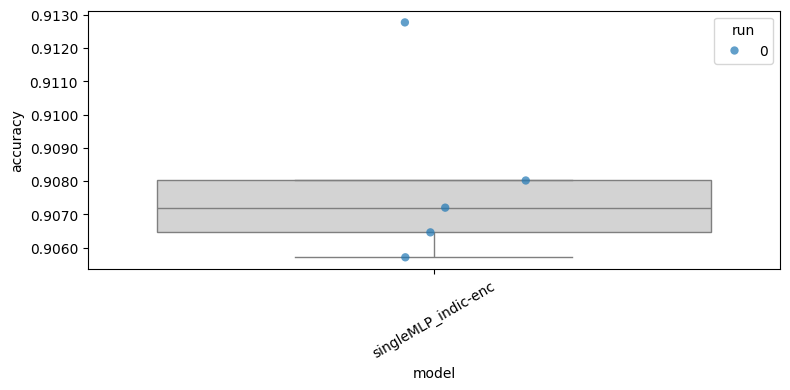

In [5]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [6]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [indicator_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = smlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=smlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/singleMLP_indic-enc/seed-{seed}/fold-{fold}/model"
        model = smlp.load(model_folder)

        smlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = smlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.7452030925575747, 'accuracy': 0.786697247706422}
              precision    recall  f1-score   support

           0       0.82      0.73      0.77       428
           1       0.76      0.84      0.80       444

    accuracy                           0.79       872
   macro avg       0.79      0.79      0.79       872
weighted avg       0.79      0.79      0.79       872

{'loss': 0.658117693498594, 'accuracy': 0.783256880733945}
              precision    recall  f1-score   support

           0       0.81      0.73      0.77       428
           1       0.76      0.83      0.80       444

    accuracy                           0.78       872
   macro avg       0.79      0.78      0.78       872
weighted avg       0.79      0.78      0.78       872

{'loss': 0.7104710056147444, 'accuracy': 0.7775229357798165}
              precision    recall  f1-score   support

           0       0.78      0.77      0.77       428
           1       0.78      0.79      0.78       444

  

In [7]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)